In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *



import matplotlib as mpl
mpl.rcParams["font.size"] = 18

dir_save_data = r'H:\commun\Utilisateur FNO\Nathan\Conference\2026-04-24 RJP\Figures'
save_fig = 0

## Plot linear spectra of ND

### Spectre pour l'introduction sur la SMS

In [2]:
### Get calib

dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']


#Get spectra
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Silice thick 4,5 - D1 zone1' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_170', force_recomputation=False, spectra_title = '31-Mar-2025_Spectre_theta_0', method='fine')

data = Spectra_Data['ND']


## Plot spectra

#fit data
Res_fit = Lorentz_fit_energy_spectra(data)



Linear spectra already treated


Get the Plot info data

Big size spectra figure

### Q-factor ND PaP signal

In [3]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Detailed acoustic mode study\NDd zone 3\-1300ps to 0 ps'
dir_name = r'2025-12-19_PaP_Pp20uW_ldap410nm_ldas660nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'


dir_save_treated_data = dir_root + '\\' + dir_name


Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

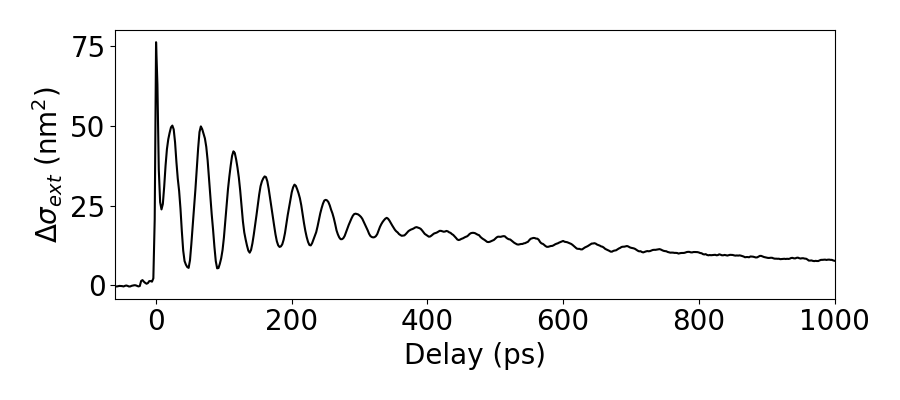

In [4]:
alpha_DTT_dsigma = -172035.5417065772 #conversion coefficient from DTT to delta sigma in nm2

mpl.rcParams["font.size"] = 20
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot[10:], (Trace.DTT_tot[10:] - Trace.mean_start)*alpha_DTT_dsigma,  color = 'black')


ax.set_xlim((-60, 1000))

ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')
ax.set_xlabel('Delay (ps)')
#ax.grid('on')
fig.patch.set_facecolor( '#FF000000' )
plt.tight_layout()


os.chdir(dir_save_data)
if save_fig :
    plt.savefig('PaP total signal on quartz.svg')

## Quality factor study

big version

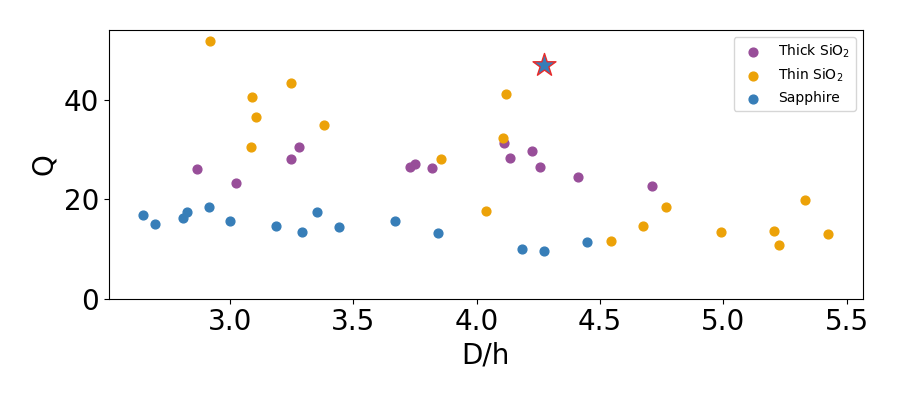

In [5]:
mpl.rcParams["font.size"] = 20

fname='Treated_data'
Geometry_choice = 'round'
h=21

Data = {}
Color_dic = {}
dir_1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR_estimation\ND_measurements_AR_treated'
data_name_1 = r'Thick SiO$_2$'
Data[data_name_1] = get_treated_AR_data(dir_1, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_1] = '#984E99'


dir_3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice membrane\AR_estimation\ND_measurements_AR_treated'
data_name_3 = r'Thin SiO$_2$'
Data[data_name_3] = get_treated_AR_data(dir_3, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_3] = "#ECA208"

dir_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements_AR_treated'
data_name_2 = 'Sapphire'
Data[data_name_2] = get_treated_AR_data(dir_2, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_2] = '#377EB8'

## Make the plot
fig, ax = plt.subplots(figsize = (9,4))
for key in Data :
        data = Data[key]




        compt=0
        for kkey in data :
            spectra = data[kkey]

            if spectra['Q'] != 0 :
                if compt==0 :
                    ax.scatter(spectra['2D']['AR'], spectra['Q'], c = Color_dic[key], label=key, s=40)
                else :
                    ax.scatter(spectra['2D']['AR'], spectra['Q'], c = Color_dic[key], s=40)

                #ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color=Color_dic[key])
            compt+=1
ax.scatter(4.27313, 47, facecolor='#377EB8', edgecolor="#E82B2B", marker = '*', s=300)
ax.set_xlabel('D/h')
ax.set_ylabel('Q')
#ax.grid()



ax.set_ylim(bottom = 0)
plt.legend(fontsize = 10)
plt.tight_layout()
plt.show()
fig.patch.set_facecolor( '#FF000000' )
os.chdir(dir_save_data)
if save_fig :
        
    plt.savefig('Q_factor_study_big.svg')


small version

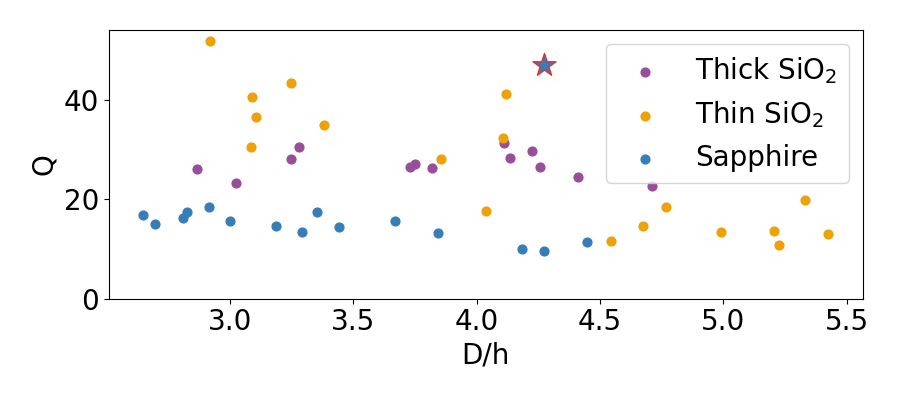

In [6]:
mpl.rcParams["font.size"] = 20

fname='Treated_data'
Geometry_choice = 'round'
h=21

Data = {}
Color_dic = {}
dir_1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR_estimation\ND_measurements_AR_treated'
data_name_1 = r'Thick SiO$_2$'
Data[data_name_1] = get_treated_AR_data(dir_1, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_1] = '#984E99'


dir_3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice membrane\AR_estimation\ND_measurements_AR_treated'
data_name_3 = r'Thin SiO$_2$'
Data[data_name_3] = get_treated_AR_data(dir_3, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_3] = "#ECA208"

dir_2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\ND_measurements_AR_treated'
data_name_2 = 'Sapphire'
Data[data_name_2] = get_treated_AR_data(dir_2, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
Color_dic[data_name_2] = '#377EB8'

## Make the plot
fig, ax = plt.subplots(figsize = (9,4))
for key in Data :
        data = Data[key]




        compt=0
        for kkey in data :
            spectra = data[kkey]

            if spectra['Q'] != 0 :
                if compt==0 :
                    ax.scatter(spectra['2D']['AR'], spectra['Q'], c = Color_dic[key], label=key, s=40)
                else :
                    ax.scatter(spectra['2D']['AR'], spectra['Q'], c = Color_dic[key], s=40)

                #ax.errorbar(spectra['1D_estimation_Aire_SPR']['AR'], spectra['Q'], yerr = spectra['Q_err'], color=Color_dic[key])
            compt+=1


ax.scatter(4.27313, 47, facecolor='#377EB8', edgecolor="#E82B2B", marker = '*', s=300)
ax.set_xlabel('D/h')
ax.set_ylabel('Q')
#ax.grid()


ax.set_ylim(bottom = 0)
plt.legend(fontsize = 20)
plt.tight_layout()
plt.show()

os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
if save_fig :
    plt.savefig('Q_factor_study_small.svg')

### 2 PaP signal for same ND geometry

### Compoisition effect : NDb zone-Sylvie (Sapphire) / ND7 zone 1 (Silice thick)

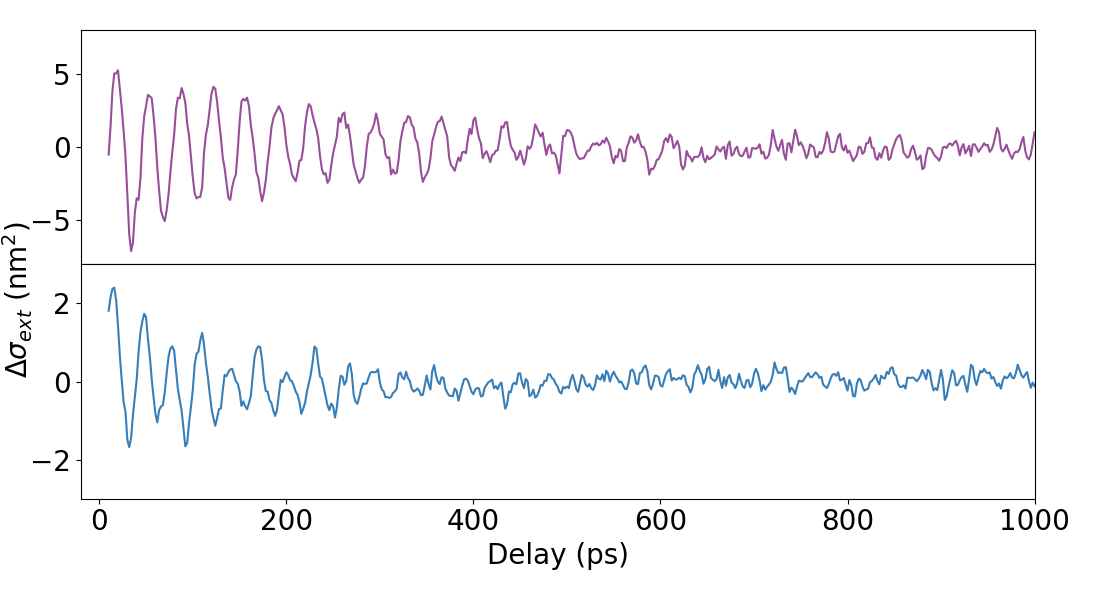

In [7]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR2.3\zone1\NDe\Etude 2025 Dec'
dir_name = r'09-Dec-2025_PaP_Pp10uW_ldap410nm_ldas610nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_NDb = get_PaP_dataset(dir_root + '\\' + dir_name, filename)



dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice thick\AR 3.5\zone-M1\D1'
dir_name = r'02-Jun-2025_PaP_Pp10uW_ldap410nm_ldas590nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND7 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


coeff_NDb = -162005.04501576335 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND7 = -149909.91712141613


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[0].plot(Trace_ND7.delay, Trace_ND7.DTT_acoustic*coeff_ND7,  color = '#984E99')
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[1].plot(Trace_NDb.delay, Trace_NDb.DTT_acoustic*coeff_NDb,  color = '#377EB8')


ax[1].set_ylim((-3,3))
ax[0].set_ylim((-8, 8))

ax[0].set_xlim((-20, 1000))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
if save_fig :
    plt.savefig('2 PaP signals - composition effect.svg')

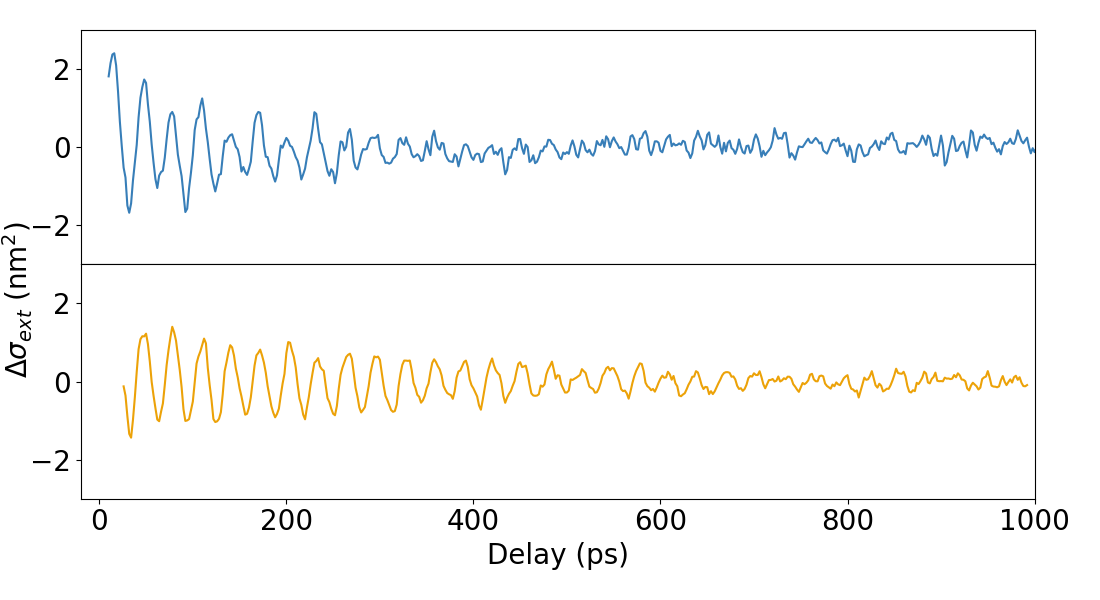

In [8]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR2.3\zone1\NDe\Etude 2025 Dec'
dir_name = r'09-Dec-2025_PaP_Pp10uW_ldap410nm_ldas610nm'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_NDb = get_PaP_dataset(dir_root + '\\' + dir_name, filename)



dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Silice membrane\AR2.3gridA1\AR2.3-3\20240201_pr584nm_pp410nm_Ppp=6uw_pol90'
dir_name = r'Traces'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'



Trace_ND7 = get_PaP_dataset(dir_root + '\\' + dir_name, filename)


coeff_NDb = -162005.04501576335 #conversion coefficient from DTT to delta sigma in nm2
coeff_ND7 = -140957.54479825342


mpl.rcParams["font.size"] = 20
fig,ax = plt.subplots(figsize=(11, 6),nrows=2, sharex=True)
# set height ratios for subplots





#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax[1].plot(Trace_ND7.delay, Trace_ND7.DTT_acoustic*coeff_ND7,  color = "#ECA208")
#ax[0].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


ax[0].plot(Trace_NDb.delay, Trace_NDb.DTT_acoustic*coeff_NDb,  color = '#377EB8')


ax[0].set_ylim((-3,3))
ax[1].set_ylim((-3, 3))

ax[1].set_xlim((-20, 1000))

ax[1].set_xlabel('Delay (ps)')
plt.tight_layout()
fig.text(0, 0.5, r'$\Delta \sigma_{ext}$ (nm$^2$)', va='center', rotation='vertical')


plt.subplots_adjust(hspace=.0)
#ax[1].plot(Trace.delay, Osc1(Trace.delay,*Trace.acoustic_fit['1 modes']['coeffs'])*alpha_DTT_dsigma, 'r-', color= "#FF2121", linestyle='--',label=r'f = 20 GHz' +  "\n" + 'Q = 26')


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
if save_fig :
    plt.savefig('2 PaP signals - composition effect v2.svg')

## Plot a PaP signal

In [9]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

dir_name = r'6-Fev-2025_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_610'
dir_name += '_treated'
filename = 'Trace_acoustic_fitted'
Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

dir_root2 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'

dir_name2 = r'22-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_640'
dir_name2 += '_treated'
filename2 = 'Trace_acoustic_fitted'
Trace2 = get_PaP_dataset(dir_root2 + '\\' + dir_name2, filename2)

dir_root3 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name3 = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name3 += '_treated'
filename3 = 'Trace_acoustic_fitted'
Trace3 = get_PaP_dataset(dir_root3 + '\\' + dir_name3, filename3)

dir_root4 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3\PaP_study'
#dir_name = r'30-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_680'
dir_name4 = r'21-Jan-2021_PaP_Pp_6uW_theta_0_tau_100ms_Vapd_3,7_V_Ldas_660'
dir_name4 += '_treated'
filename4 = 'Trace_acoustic_fitted'
Trace4 = get_PaP_dataset(dir_root4 + '\\' + dir_name4, filename3)

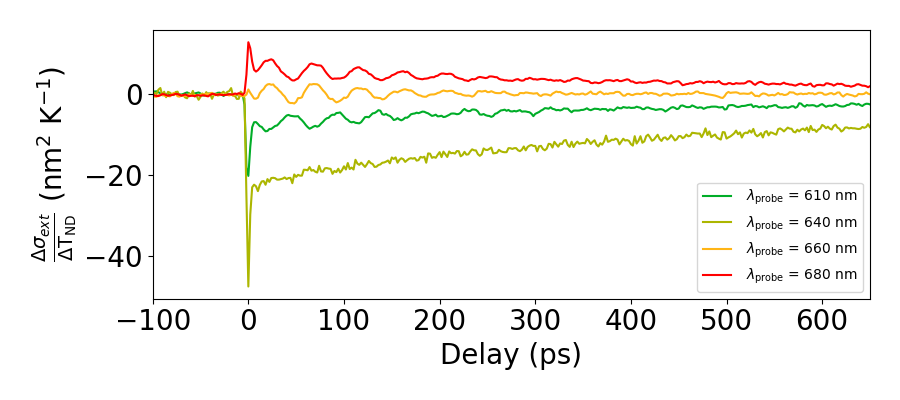

In [10]:
alpha_1 = -162005.04502 #conversion coefficient from DTT to delta sigma in nm2
alpha_2 = -173700.41189
alpha_3 = -182602.07738
alpha_4 = -178029.6157


dT1 = 2.95879 #650nm and less
dT2 = 4.73479 #660 nm and more
fig, ax = plt.subplots(figsize = (9,4))

#ax[0].scatter(Trace.delay_tot, Trace.DTT_tot*1e5, s=5, color = 'black',label= 'Mean trace')
ax.plot(Trace.delay_tot, Trace.DTT_tot*alpha_1/dT1,  color = "#00AD28", label=r' $\lambda_\mathrm{probe}$ = 610 nm')
ax.set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)')

#ax.grid('on')

ax.plot(Trace2.delay_tot[:400], Trace2.DTT_tot[:400]*alpha_2/dT1,  color = "#ACB600", label = r' $\lambda_\mathrm{probe}$ = 640 nm')




ax.plot(Trace4.delay_tot, Trace4.DTT_tot*alpha_3/dT2,  color = "#FFB516", label = r' $\lambda_\mathrm{probe}$ = 660 nm')



ax.plot(Trace3.delay_tot, Trace3.DTT_tot*alpha_4/dT2,  color = "#FF0000", label=r' $\lambda_\mathrm{probe}$ = 680 nm')
ax.set_ylabel(r'$\frac{\Delta \sigma_{ext}}{\Delta \mathrm{T_{ND}}}$ (nm$^2$ K$^{-1}$)')
ax.set_xlabel('Delay (ps)')


plt.xlim(left=-100, right=650)
plt.legend(fontsize=10)
fig.patch.set_facecolor( '#FF000000' )


plt.tight_layout()


os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
if save_fig :
    plt.savefig('PaP signal 4 wavelengths.svg')

## Thermal and Acoustic sensitivity

## Linear spectra of ND

## Plot Spectra of Sapphire ND

In [11]:
Plot_info = {}
Plot_info['fontsize'] = 25



Plot_info['Markers'] = {}
Plot_info['Markers']['SHG'] = 'v'
Plot_info['Markers']['OPO'] = '.'
Plot_info['Markers']['CHA'] = '*'
Plot_info['Markers']['Maitai'] = '*'

Plot_info['Couleurs'] = {}
Plot_info['Couleurs']['SHG'] = ["#004b6b", '#9dc6e0']
Plot_info['Couleurs']['OPO'] = ['#488f31', '#b6ccab']
Plot_info['Couleurs']['CHA'] = ['#de425b', '#efb7b8']
Plot_info['Couleurs']['Maitai'] = ['#de425b', '#efb7b8']

Col='#488f31'

In [12]:
## Calibration data

dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'

Source_list = ['OPO', 'SHG']
FWHM_data = get_FWHM_data(dir_calib, Source_list)
WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']




# Spectra data
delta_y = 300e-9

Spectra_Data = {}

dir_root1 = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Sapphire 2,3 - NDd zone 3' 

Spectra_Data['ND'] = Spectra_computation(dir_root1, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_0', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_0', method='fine')

data = Spectra_Data['ND']

Linear spectra already treated


Big size spectra figure

Small size spectra figure

NameError: name 'ax2' is not defined

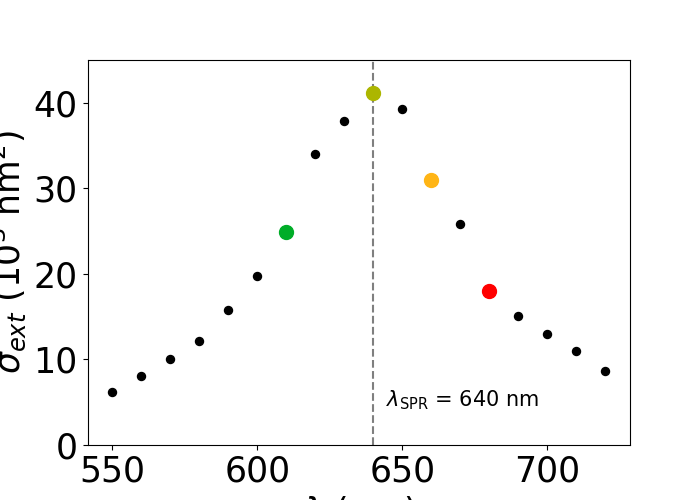

In [13]:
mpl.rcParams["font.size"] = 25

s_size=100

fig, ax = plt.subplots(figsize=(7,5))    

for source_key in data['Source_list'] :

    plt.scatter((data['Lambda'][source_key])*1e9, data['Sigma'][source_key]*1e15,s = s_size/3,color='black', label=source_key, zorder=1)
    

    #plt.errorbar(1240/(data['Lambda'][source_key]*1e9), data['Sigma'][source_key]*1e15, yerr = data['Sigma_err'][source_key]*1e15, linestyle='',alpha=0.3, color=Col)



    for i in range(len(data['Lambda'][source_key])) :
        lda = int(data['Lambda'][source_key][i]*1e9)
        
        if lda == 610 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#00AD28", label=source_key, zorder=2)
        if lda == 640 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#ACB600", label=source_key, zorder=2)
        if lda == 660 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#FFB516", label=source_key, zorder=2)
        if lda == 680 :
            plt.scatter((data['Lambda'][source_key][i])*1e9, data['Sigma'][source_key][i]*1e15,s = s_size,color="#FF0000", label=source_key, zorder=2)


ax.text(0.55, 0.1, r'$\lambda_\mathrm{SPR}$ = 640 nm', fontsize=15,  transform=ax.transAxes)
plt.axvline(640, linestyle='--',alpha=0.5, color='black', zorder=0)


plt.ylim(bottom = 0, top=45)
#plt.xlim((550, 750))
plt.ylabel(r"$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel(r'$\lambda$ (nm)')

fig.patch.set_facecolor( '#FF000000' )
ax2.set_xlabel("Lambda (nm)")
#plt.grid('on')
plt.subplots_adjust(top=0.7)
#plt.title(data['title'])
#plt.legend()
plt.tight_layout()

mpl.rcParams["font.size"] = 18

os.chdir(dir_save_data)
fig.patch.set_facecolor( '#FF000000' )
if save_fig :
    plt.savefig('Nd_Sapphire Spectra (small).svg')